In [3]:
import pickle
import numpy as np
import random
import matplotlib.pyplot as plt  # 添加这行导入

from sklearn.preprocessing import StandardScaler
import umap

# 固定所有随机种子为42（确保实验可复现）
random.seed(42)       # Python内置随机模块
np.random.seed(42)    # NumPy随机数生成

## 读取书数据
with open("/home/baolingjie/git_download/NMR_Core_Mol_Detection/data/enumerate_100m_5m_1_group_restricted/last_results.pkl", "rb") as f:
    data = pickle.loads(f.read())

## 过滤数据
count = 0
for _ in data:
    if len(list(set(_["C_nmr"])))>0:
        count = count + 1
print(f"len(data):{len(data)}, count:{count}")



len(data):522904, count:522887


In [5]:
import torch

try:
    torch.serialization.add_safe_globals([np._core.multiarray._reconstruct, np.ndarray, np.dtype])
except Exception as e:
    print(e)
data_dict = torch.load("/home/baolingjie/git_download/NMR_Core_Mol_Detection/data/enumerate_100m_5m_1_group_restricted/last_results_processed_cress.pt", weights_only=False)

In [9]:
len(data_dict), len(data_)

(522887, 522887)

In [13]:
index = random.sample(range(len(data_dict)), min(20000, len(data_)))
data_ = [_ for _ in data if len(list(set(_["C_nmr"])))>0]
data_ = [data_[_] for _ in index] #100000
nmr_fp_array = np.concatenate([data_dict[_] for _ in index])

In [14]:
nmr_fp_array.shape

(20000, 768)

In [17]:


## 命名
query_dict = {
    # 'alkene': 5,
    'alcohol': 2,
    'amide': 10,
    'ester': 37,
    # 'ketone': 50,
    'sulfide': 80,
    'ether': 38,
    'pyridyl': 72,
    'hydrocarbon': 41,
    'amine': 12,
    'sulfone': 83,
    'aldehyde': 3,
    'polyol': 68,
    'nitro': 56,
    #  'secondary_amine': 76,
    'haloalkane': 40,
    #  'alkyne': 9,
    #  'tertiary_amine': 86
}

query_name = [v for v in query_dict.keys()]
query_list = [v for v in query_dict.values()]
print(f"query_name:{query_name}, query_list:{query_list}")

## 计算
labels = [query_name[list(_["function_list"][query_list]).index(1)] for _ in data_]
function_array = np.array([_["function_list"] for _ in data_])
function_array = function_array[:,query_list]

print(f"labels:{len(labels)}, function_array:{function_array.shape}")




query_name:['alcohol', 'amide', 'ester', 'sulfide', 'ether', 'pyridyl', 'hydrocarbon', 'amine', 'sulfone', 'aldehyde', 'polyol', 'nitro', 'haloalkane'], query_list:[2, 10, 37, 80, 38, 72, 41, 12, 83, 3, 68, 56, 40]
labels:20000, function_array:(20000, 13)


In [44]:
np.unique(labels)

array(['alcohol', 'aldehyde', 'amide', 'amine', 'ester', 'ether',
       'haloalkane', 'hydrocarbon', 'nitro', 'pyridyl', 'sulfide',
       'sulfone'], dtype='<U11')

In [119]:
selected_label = ['sulfone','pyridyl']
labels_ = [_ for _ in labels if _ in selected_label]
nmr_fp_array_ = np.stack([_ for i,_ in enumerate(nmr_fp_array) if labels[i] in selected_label])

In [116]:
# 3. 标准化数据（UMAP对尺度敏感）
scaler = StandardScaler()
scaled_data_ = scaler.fit_transform(nmr_fp_array_)

In [117]:
from sklearn.decomposition import PCA
# PCA降维
reducer = PCA(
    n_components=2,          # 降维到2D
    random_state=42
)
embedding = reducer.fit_transform(scaled_data_)

/tmp/ipykernel_1446940/1535453422.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）
/tmp/ipykernel_1446940/1535453422.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


(np.float64(-19.496192073822023),
 np.float64(22.84269437789917),
 np.float64(-21.37844705581665),
 np.float64(20.72783327102661))

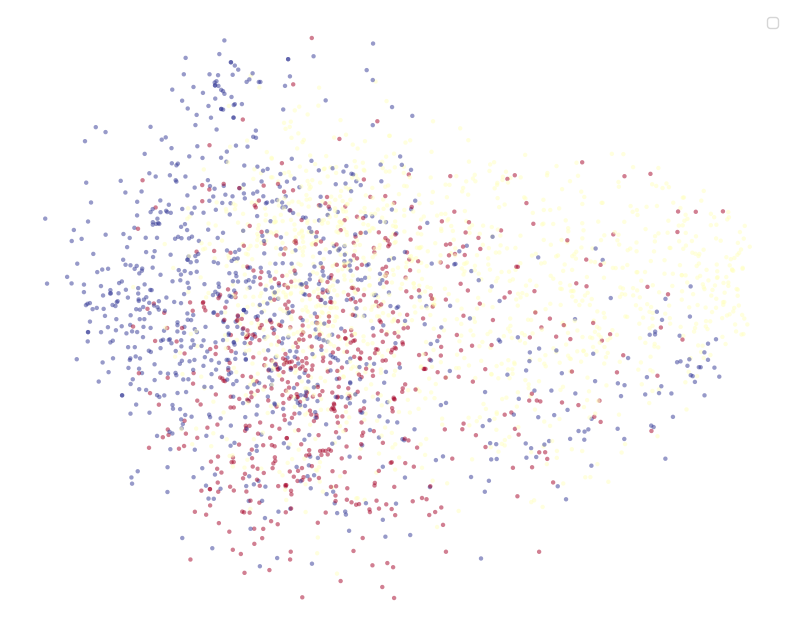

In [118]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
numeric_labels = label_encoder.fit_transform(labels_)  # 转换为0,1,2,...

# 2. 创建颜色映射
unique_labels = np.unique(labels_)
num_categories = len(unique_labels)
colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）

# 3. 绘制散点图
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding[:, 0], 
    embedding[:, 1],
    c=numeric_labels,          # 使用数值标签
    cmap=colormap,             # 颜色映射
    alpha=0.5,                # 透明度
    s=10,                     # 点大小
    edgecolor='none'           # 完全无边框
)

# 4. 添加颜色条
# cbar = plt.colorbar(scatter)
# cbar.set_ticks(range(num_categories))  # 设置刻度位置
# cbar.set_ticklabels(unique_labels)      # 设置刻度标签
# cbar.set_label('Functional Group', rotation=270, labelpad=15)

# 5. 添加标题和标签
# plt.title("Chemical Fingerprint UMAP Projection", fontsize=14)
# plt.xlabel("UMAP Dimension 1", fontsize=12)
# plt.ylabel("UMAP Dimension 2", fontsize=12)
plt.legend()

plt.axis('off')

In [91]:
unique_labels

array(['aldehyde', 'haloalkane'], dtype='<U10')

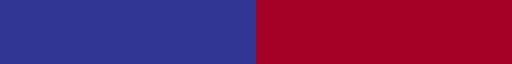

In [92]:
colormap

In [97]:
# 3. 标准化数据（UMAP对尺度敏感）
scaler = StandardScaler()
scaled_data = scaler.fit_transform(nmr_fp_array)

In [98]:


reducer = umap.UMAP(
    n_components=2,          # 降维到2D
    n_neighbors=15,          # 局部结构的邻居数
    min_dist=0.1,            # 控制点聚集程度
    metric='euclidean',      # 距离度量
    random_state=30,
    # n_jobs=20
)
embedding = reducer.fit_transform(scaled_data)

/home/baolingjie/anaconda3/envs/py310_v2/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/tmp/ipykernel_1446940/741555001.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）
/tmp/ipykernel_1446940/741555001.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


(np.float64(-2.817698931694031),
 np.float64(10.211420035362243),
 np.float64(-3.100856602191925),
 np.float64(7.001962244510651))

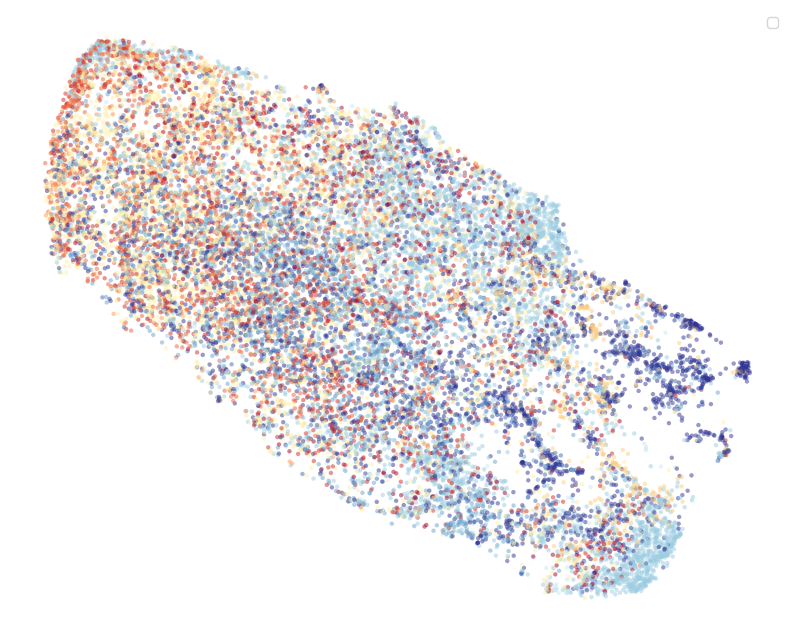

In [99]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
numeric_labels = label_encoder.fit_transform(labels)  # 转换为0,1,2,...

# 2. 创建颜色映射
unique_labels = np.unique(labels)
num_categories = len(unique_labels)
colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）

# 3. 绘制散点图
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding[:, 0], 
    embedding[:, 1],
    c=numeric_labels,          # 使用数值标签
    cmap=colormap,             # 颜色映射
    alpha=0.5,                # 透明度
    s=10,                     # 点大小
    edgecolor='none'           # 完全无边框
)

# 4. 添加颜色条
# cbar = plt.colorbar(scatter)
# cbar.set_ticks(range(num_categories))  # 设置刻度位置
# cbar.set_ticklabels(unique_labels)      # 设置刻度标签
# cbar.set_label('Functional Group', rotation=270, labelpad=15)

# 5. 添加标题和标签
# plt.title("Chemical Fingerprint UMAP Projection", fontsize=14)
# plt.xlabel("UMAP Dimension 1", fontsize=12)
# plt.ylabel("UMAP Dimension 2", fontsize=12)
plt.legend()

plt.axis('off')
# plt.grid(alpha=0.2)

In [120]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
numeric_labels = label_encoder.fit_transform(labels)  # 转换为0,1,2,...

# 2. 创建颜色映射
unique_labels = np.unique(labels)
num_categories = len(unique_labels)
colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）

# 创建筛选掩码
mask = np.array([label in selected_labels for label in labels])

# 筛选数据
filtered_embedding = embedding[mask]
filtered_labels = np.array(labels)[mask]

# 3. 绘制散点图
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding[:, 0][_ for _ in labels if _ in selected_label], 
    embedding[:, 1][_ for _ in labels if _ in selected_label],
    c=numeric_labels,          # 使用数值标签
    cmap=colormap,             # 颜色映射
    alpha=0.5,                # 透明度
    s=10,                     # 点大小
    edgecolor='none'           # 完全无边框
)

# 4. 添加颜色条
# cbar = plt.colorbar(scatter)
# cbar.set_ticks(range(num_categories))  # 设置刻度位置
# cbar.set_ticklabels(unique_labels)      # 设置刻度标签
# cbar.set_label('Functional Group', rotation=270, labelpad=15)

# 5. 添加标题和标签
# plt.title("Chemical Fingerprint UMAP Projection", fontsize=14)
# plt.xlabel("UMAP Dimension 1", fontsize=12)
# plt.ylabel("UMAP Dimension 2", fontsize=12)
plt.legend()

plt.axis('off')

SyntaxError: invalid syntax. Perhaps you forgot a comma? (192457288.py, line 13)

In [100]:
from sklearn.decomposition import PCA
# PCA降维
reducer = PCA(
    n_components=2,          # 降维到2D
    random_state=42
)
embedding = reducer.fit_transform(scaled_data)

/tmp/ipykernel_1446940/1275058741.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）
/tmp/ipykernel_1446940/1275058741.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


(np.float64(-20.02642765045166),
 np.float64(23.1969331741333),
 np.float64(-22.672469902038575),
 np.float64(23.496105003356934))

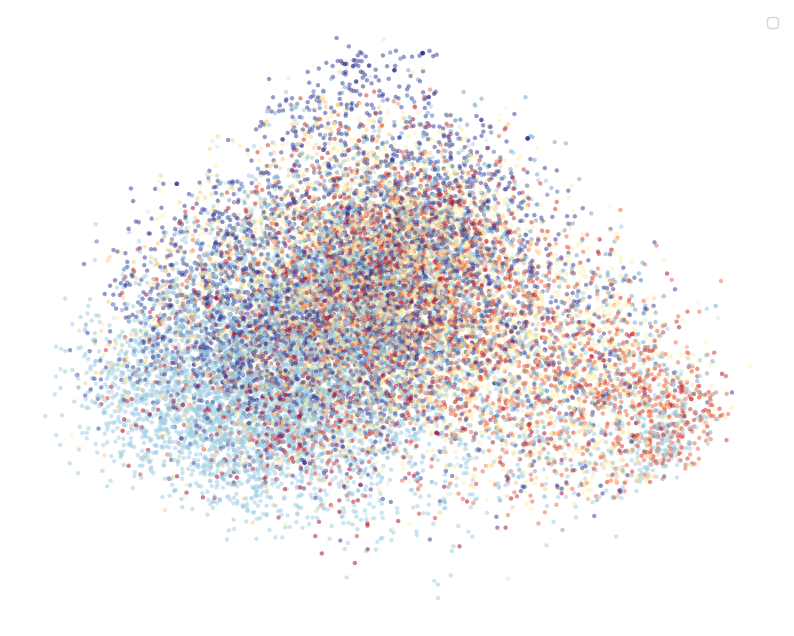

In [101]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
numeric_labels = label_encoder.fit_transform(labels)  # 转换为0,1,2,...

# 2. 创建颜色映射
unique_labels = np.unique(labels)
num_categories = len(unique_labels)
colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）

# 3. 绘制散点图
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding[:, 0], 
    embedding[:, 1],
    c=numeric_labels,          # 使用数值标签
    cmap=colormap,             # 颜色映射
    alpha=0.5,                # 透明度
    s=10,                     # 点大小
    edgecolor='none'           # 完全无边框
)

# 4. 添加颜色条
# cbar = plt.colorbar(scatter)
# cbar.set_ticks(range(num_categories))  # 设置刻度位置
# cbar.set_ticklabels(unique_labels)      # 设置刻度标签
# cbar.set_label('Functional Group', rotation=270, labelpad=15)

# 5. 添加标题和标签
# plt.title("Chemical Fingerprint UMAP Projection", fontsize=14)
# plt.xlabel("UMAP Dimension 1", fontsize=12)
# plt.ylabel("UMAP Dimension 2", fontsize=12)
plt.legend()

plt.axis('off')

In [102]:
unique_labels

array(['alcohol', 'aldehyde', 'amide', 'amine', 'ester', 'ether',
       'haloalkane', 'hydrocarbon', 'nitro', 'pyridyl', 'sulfide',
       'sulfone'], dtype='<U11')

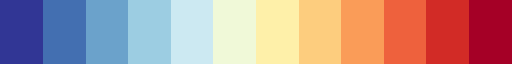

In [32]:
colormap

In [1]:
from sklearn.manifold import TSNE

reducer = TSNE(
    n_components=2,
    perplexity=30,           # 典型值在5-50之间
    learning_rate='auto',     # 自动调整或设为200
    # n_iter=1000,             # 迭代次数
    random_state=42,
    init='pca',              # 使用PCA初始化
    metric='euclidean'       # 距离度量
)
embedding = reducer.fit_transform(scaled_data)

NameError: name 'scaled_data' is not defined

In [ ]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
numeric_labels = label_encoder.fit_transform(labels)  # 转换为0,1,2,...

# 2. 创建颜色映射
unique_labels = np.unique(labels)
num_categories = len(unique_labels)
colormap = plt.cm.get_cmap('coolwarm', num_categories)  # 也可用 'tab10'（最多10类）

# 3. 绘制散点图
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding[:, 0], 
    embedding[:, 1],
    c=numeric_labels,          # 使用数值标签
    cmap=colormap,             # 颜色映射
    alpha=0.7,                # 透明度
    s=20,                     # 点大小
    edgecolor='none'           # 完全无边框
)

# 4. 添加颜色条
# cbar = plt.colorbar(scatter)
# cbar.set_ticks(range(num_categories))  # 设置刻度位置
# cbar.set_ticklabels(unique_labels)      # 设置刻度标签
# cbar.set_label('Functional Group', rotation=270, labelpad=15)

# 5. 添加标题和标签
# plt.title("Chemical Fingerprint UMAP Projection", fontsize=14)
# plt.xlabel("UMAP Dimension 1", fontsize=12)
# plt.ylabel("UMAP Dimension 2", fontsize=12)
plt.legend()

plt.axis('off')